# GlobalForms metric pilot

Run the notebook with a review manifest. Track A compares recovered form structure to a reference spec. Track B compares submitted completions to the scenario’s expected answers. Each figure and error flag is calculated from the selected bundle.

The default incident examples are synthetic. Set `GLOBALFORMS_FIXTURE` to a manifest path before starting Jupyter to review another PDF. The included `fixtures/locker/review.json` exercises an independent form on page 2. Matching thresholds, treatment of ambiguous cases and final competition weights are provisional.

In [1]:
import json
import os
import re
from pathlib import Path

from IPython.display import HTML, Markdown, display

from globalforms.fixtures import load_review, read_page
from globalforms.spec_view import formspec_html
from globalforms.metrics import (
    SCORER_VERSION, TrackAFlag, TrackBFlag, f1,
    track_a, track_a_flags, track_b, track_b_flags,
)

review_path = Path(os.environ.get("GLOBALFORMS_FIXTURE", "fixtures/incident/review.json")).resolve()
review = load_review(review_path)
review_spec = review.reference
reference = review_spec.model_dump(exclude_unset=True)
output_dir = Path("output") / review_path.parent.name
print(f"Reviewing {review_path.parent.name}/{review_path.name} · page {review.page}")

def show_spec_changes(reference_spec, predicted_spec):
    comparison = formspec_html(reference_spec, predicted_spec, changed_only=True)
    display(HTML(f"<details><summary>Compare changed FormSpec entries</summary>{comparison}</details>"))


def show_flag_matrix(flag_type, cases, *, accuracy=()):
    if not cases:
        return
    titles = [title.replace("|", "&#124;") for title, _ in cases]
    rows = [["Flag", *titles], ["---"] * (len(titles) + 1)]
    for flag in flag_type:
        rows.append([flag.label, *(str(int(flags[flag])) for _, flags in cases)])
    if accuracy:
        rows.append(["Answer accuracy", *accuracy])
    display(Markdown("\n".join("| " + " | ".join(row) + " |" for row in rows)))

Reviewing locker/review.json · page 2


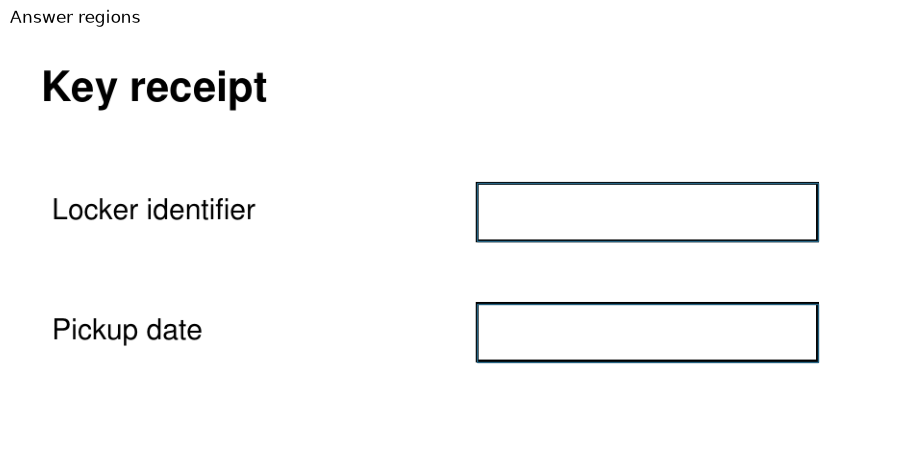

In [2]:
import matplotlib.pyplot as plt
from globalforms.overlays import compare_layer, draw_layer, draw_region_pair, page_axes, page_marks

paper, page_size = read_page(review)
page = review.page
viewport = review.crop
default_role = review.default_role
gold_marks = page_marks(review_spec, page, default_role=default_role)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
page_axes(ax, page_size, image=paper, crop=viewport)
layer = "rules" if any(mark.layer == "rules" for mark in gold_marks) else "geometry"
draw_layer(ax, gold_marks, layer)
ax.set_title("Conditional rules" if layer == "rules" else "Answer regions", loc="left")
plt.show()

## Inspect the FormSpec

The colors group the serialized spec as in the paper. Fields are blue, answer regions green, role declarations purple, rules amber and validations red. Expand the comparison under a prediction to see its changed entries alongside the reference. The comparison uses the IDs as supplied.

`regions` locate where an answer goes. `evidenceIds` cite items in `evidence`, each a page and bounding box for source material such as a label, heading or instruction. The validator checks that a cited ID exists. Track A scores answer-region geometry, and Track B can use that geometry to align recovered fields. Neither track scores the location or relevance of the cited evidence.

In [3]:
review_spec

Spec group,FormSpec
■ schemaVersion,"""pilot-1"""
■ sections,"{ ""receipt"": { ""title"": ""Key receipt"", ""evidenceIds"": [""heading""], ""role"": ""Custodian"" } }"
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} }, ""pickup"": { ""label"": ""Pickup date"", ""section"": ""receipt"", ""evidenceIds"": [""date_label""], ""regions"": [""date_box""], ""type"": ""date"", ""options"": {} } }"
■ regions,"{ ""locker_box"": {""page"": 2, ""bbox"": [190.0, 76.0, 130.0, 22.0]}, ""date_box"": {""page"": 2, ""bbox"": [190.0, 122.0, 130.0, 22.0]} }"
■ rules,[]
■ validations,"[ { ""kind"": ""iso_calendar_date"", ""fields"": [""pickup""], ""evidenceIds"": [""date_label""] } ]"
■ evidence,"{ ""heading"": {""page"": 2, ""bbox"": [24.0, 33.0, 85.0, 16.0]}, ""locker_label"": {""page"": 2, ""bbox"": [28.0, 82.0, 80.0, 11.0]}, ""date_label"": {""page"": 2, ""bbox"": [28.0, 128.0, 60.0, 11.0]} }"


## Conditional effects in the reference

Each rule shows what its controller implies for the target. Applicability determines whether the field applies. Requiredness determines whether an active field needs an answer for submission. Track B can still credit an omission when the scenario gives no answer.

In [4]:
from globalforms.metrics.track_a import choice_condition

outcomes = {
    "applicable": {True: "active", False: "inactive", None: "unresolved"},
    "required": {True: "required when active", False: "no requirement from this rule", None: "unresolved"},
}
for rule in reference["rules"]:
    controller = reference["fields"][rule["controller"]]
    effect = rule.get("effect", "applicable")
    targets = [reference["fields"][key]["label"] for key in rule.get("fields", ())]
    targets.extend(reference["sections"][key]["title"] for key in rule.get("sections", ()))
    print(f"{controller['label']} → {', '.join(targets)} ({effect})")
    for answer in [*controller["options"], None]:
        print(f"  {answer if answer is not None else 'Unanswered'} → {outcomes[effect][choice_condition(rule, answer)]}")
if not reference["rules"]:
    print("The reference declares no conditional rules.")

The reference declares no conditional rules.


## Track A on the source PDF
Each pair shows one planted change on the same source page. Scores below each pair include downstream effects of the evaluator’s field matching. In the section comparison, each outlined heading shares a color with its direct members’ answer regions. An unassigned field stays unshaded.

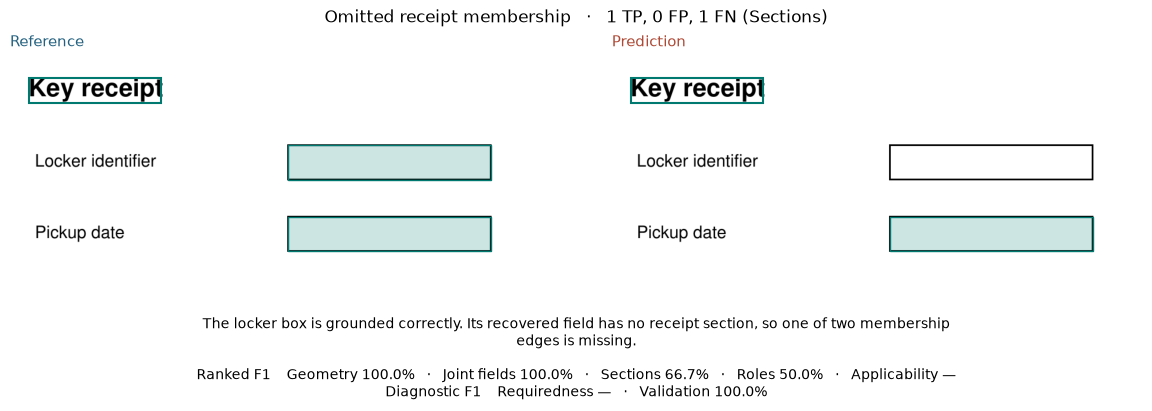

Spec group,Reference (GT),Prediction
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }","{ ""slot"": { ""label"": ""Locker identifier"", ""section"": null, ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }"


In [5]:
from textwrap import fill

plot_dir = output_dir / "track-a"
plot_dir.mkdir(parents=True, exist_ok=True)

(plot_dir / "ground-truth.json").write_text(json.dumps(reference, indent=2, ensure_ascii=False) + "\n")
recovery_flags = []

def format_score(label, counts):
    value = f1(counts)
    return f"{label} {value:.1%}" if value is not None else f"{label} —"


for index, case in enumerate(review.track_a, start=1):
    layer = case.layer
    prediction = case.spec
    candidate = prediction.model_dump(exclude_unset=True)
    predicted = page_marks(prediction, page, default_role=default_role)
    figure = compare_layer(gold_marks, predicted, layer, page_size, image=paper, crop=viewport)
    if case.inspect_regions:
        ref_region, pred_region = case.inspect_regions
        original = next(m for m in gold_marks if m.region_id == ref_region and m.layer == layer)
        shifted = next(m for m in predicted if m.region_id == pred_region and m.layer == layer)
        ref_ioa, pred_ioa = draw_region_pair(figure.axes[1], original, shifted)
        figure.axes[1].set_xlabel(f"Coverage: reference {ref_ioa:.0%}, prediction {pred_ioa:.0%}")
        print(f"Region coverage: reference {ref_ioa:.0%}, prediction {pred_ioa:.0%}")
    scores, diagnostics = track_a(candidate, reference, default_role=default_role)
    tp, fp, fn = scores[layer]
    title = case.title or layer.title()
    flags = track_a_flags(scores, diagnostics)
    recovery_flags.append((title, flags))
    figure.suptitle(f"{title}   ·   {tp} TP, {fp} FP, {fn} FN ({TrackAFlag(layer).label})")

    ranked = "   ·   ".join(format_score(TrackAFlag(key).label, counts) for key, counts in scores.items())
    diagnostic = "   ·   ".join(format_score(flag.label, diagnostics[flag])
                              for flag in (TrackAFlag.REQUIREDNESS, TrackAFlag.VALIDATION))
    caption = fill(case.explanation, width=108)
    figure.supxlabel(f"{caption}\n\nRanked F1    {ranked}\nDiagnostic F1    {diagnostic}", fontsize=10)
    stem = f"{index:02d}-{layer}"
    figure.savefig(plot_dir / f"{stem}.png", dpi=160, facecolor="white", bbox_inches="tight")
    (plot_dir / f"{stem}.predicted.json").write_text(json.dumps(candidate, indent=2, ensure_ascii=False) + "\n")
    (plot_dir / f"{stem}.scores.json").write_text(json.dumps(
        {"scorer_version": SCORER_VERSION, "components": scores, "diagnostics": diagnostics, "flags": flags}, indent=2) + "\n")
    plt.show()
    show_spec_changes(review_spec, prediction)

## Track A error matrix

A 1 means the component has at least one false positive or false negative. A single planted error can affect multiple rows through field alignment. The first five rows are ranked components. The remaining rows are diagnostics.

In [6]:
show_flag_matrix(TrackAFlag, recovery_flags)

| Flag | Omitted receipt membership |
| --- | --- |
| Geometry | 0 |
| Joint fields | 0 |
| Sections | 1 |
| Roles | 1 |
| Applicability | 0 |
| Field type | 0 |
| Field label | 0 |
| Option ownership | 0 |
| Cardinality | 0 |
| Requiredness | 0 |
| Validation | 0 |

## Track B scoring

After grounding-based alignment in B-end-to-end, each correct expected value or input status earns one point. Answer accuracy divides this count by expected fields plus entries in inactive or unmatched fields. When the reference marks an applicable answer as missing, either an omitted key or an explicit missing status earns credit. An omitted supplied answer or an incorrect answer earns zero points. A case passes only when every expected answer is correct and there are no extra entries. Each mode ranks by complete-case success rate, then answer accuracy. Coverage, active-field accuracy and inactive-entry rate remain diagnostics. Coverage measures explicit entries. Active-field accuracy also credits accepted omissions.

## Track B on the source PDF
Teal shows expected entries. Purple shows submitted entries at their predicted positions. Bracketed text denotes a reference or submitted input status.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


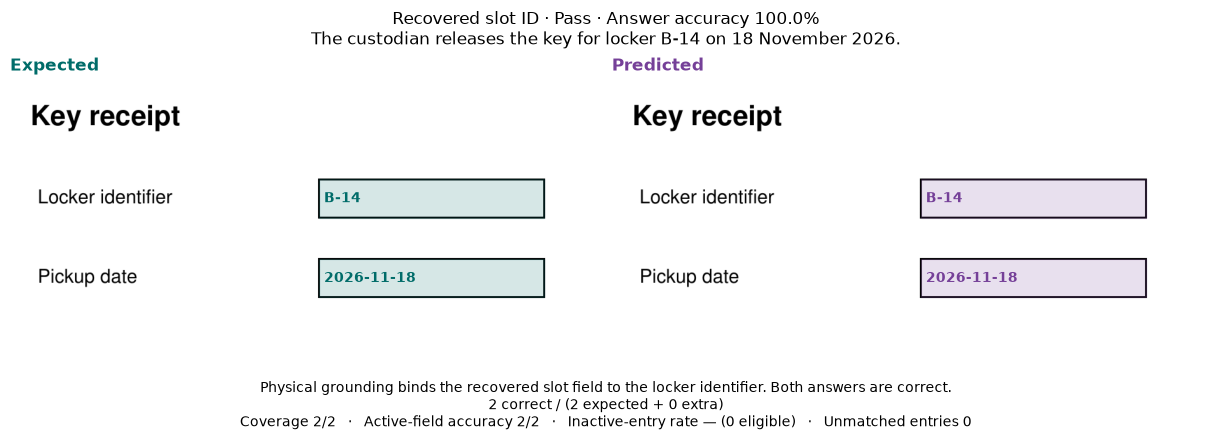

Spec group,Reference (GT),Prediction
■ fields,"{ ""locker"": { ""label"": ""Locker identifier"", ""section"": ""receipt"", ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }","{ ""slot"": { ""label"": ""Locker identifier"", ""section"": null, ""evidenceIds"": [""locker_label""], ""regions"": [""locker_box""], ""type"": ""text"", ""options"": {} } }"


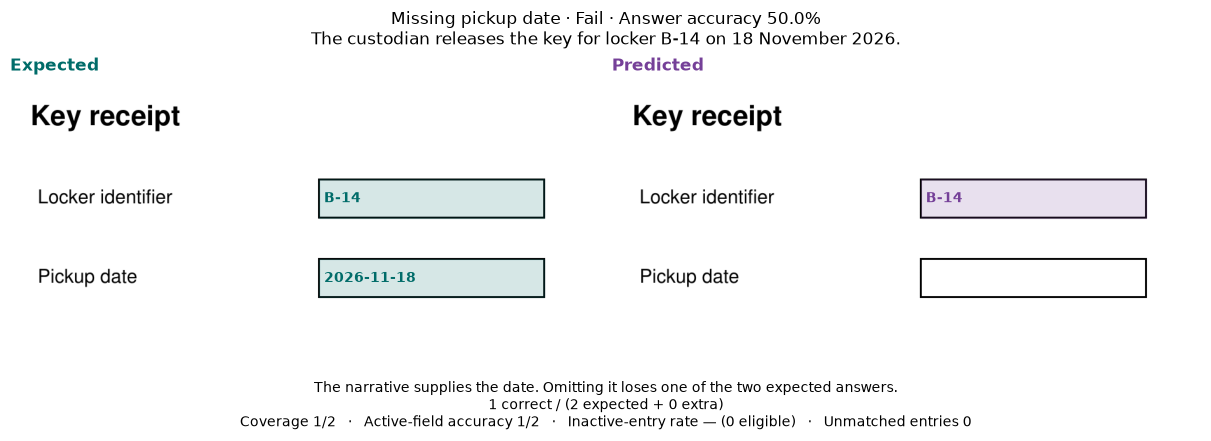

In [7]:
from globalforms.completions import answer_marks, compare_completions

completion_dir = output_dir / "track-b"
completion_dir.mkdir(parents=True, exist_ok=True)

def write_completion_json(filename, data):
    (completion_dir / filename).write_text(json.dumps(data, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

write_completion_json("ground-truth.json", reference)
completion_flags = []
answer_accuracies = []
for index, case in enumerate(review.track_b, start=1):
    title, story, explanation = case.title, case.scenario, case.explanation
    expected, submitted = case.expected, case.submitted
    predicted_spec = case.spec or review_spec
    spec_data = predicted_spec.model_dump(exclude_unset=True)
    recovered = spec_data if case.spec is not None else None
    result = track_b(submitted, expected, reference, recovered)
    drawn, _ = answer_marks(predicted_spec, submitted)
    flags = track_b_flags(result, drawable_field_ids=(mark.field_id for mark in drawn))
    completion_flags.append((title, flags))
    figure = compare_completions(review_spec, expected, predicted_spec, submitted, page=page,
                                 page_size=page_size, image=paper, crop=review.completion_crop or viewport)
    correct, denominator = result["value"]
    answer_accuracies.append(f"{correct}/{denominator}")
    extras = result["inactive"][0] + result["unmatched"]
    outcome = "Pass" if result["complete"][0] else "Fail"
    accuracy = f"{correct / denominator:.1%}" if denominator else "—"
    figure.suptitle(f"{title} · {outcome} · Answer accuracy {accuracy}\n{fill(story, width=100)}", fontsize=12)
    diagnostics = []
    for key, label in (("coverage", "Coverage"), ("activity", "Active-field accuracy"),
                       ("inactive", "Inactive-entry rate")):
        hits, total = result[key]
        ratio = f"{hits}/{total}" if total else "— (0 eligible)"
        diagnostics.append(f"{label} {ratio}")
    diagnostics.append(f"Unmatched entries {result['unmatched']}")
    formula = f"{correct} correct / ({len(expected)} expected + {extras} extra)"
    figure.supxlabel("\n".join([fill(explanation, width=105), formula, "   ·   ".join(diagnostics)]), fontsize=10)
    stem = f"{index:02d}-" + re.sub(r"[^\w-]+", "-", title.casefold()).strip("-")
    figure.savefig(completion_dir / f"{stem}.png", dpi=160, facecolor="white", bbox_inches="tight")
    write_completion_json(f"{stem}.predicted.json", spec_data)
    write_completion_json(f"{stem}.case.json", dict(scorer_version=SCORER_VERSION, title=title, scenario=story, explanation=explanation,
                          mode="B-end-to-end" if recovered is not None else "B-oracle",
                          expected=expected, submitted=submitted, scores=result, flags=flags))
    plt.show()
    if case.spec is not None:
        show_spec_changes(review_spec, case.spec)

## Track B error matrix
Each column is one filled-form comparison. A 1 means the event occurred at least once. Flags may overlap. The observation rows explain why two identical blanks can score differently and why both kinds of unknown entry receive the same penalty. Accuracy uses the underlying counts.

In [8]:
show_flag_matrix(TrackBFlag, completion_flags, accuracy=answer_accuracies)

| Flag | Recovered slot ID | Missing pickup date |
| --- | --- | --- |
| Omitted a supplied answer | 0 | 1 |
| Filled an inactive field | 0 | 0 |
| Submitted an unknown field | 0 | 0 |
| Any scoring error | 0 | 1 |
| Left an expected field blank (observation) | 0 | 1 |
| Unknown entry has a drawable box (observation) | 0 | 0 |
| Answer accuracy | 2/2 | 1/2 |

## Where the metrics may disagree with reviewers

| Comparison | Expected metric response | Human judgment to collect |
|---|---|---|
| Exact versus displaced answer box | Geometry, joint fields and downstream correspondence can all fall | Can a person still tell where to write? Could downstream use place an answer correctly? |
| Identical boxes, swapped option ownership | Geometry ties, joint fields falls | Would either wrong mapping make the form unusable? |
| Correct memberships, swapped section titles | Current section component ties | Does the task require correct section identity as conveyed to an agent or reviewer? |
| Inherited office role versus per-field office roles | Track A ties | Are the responsibilities identical? |
| Equivalent Yes / not-No rule | Track A ties when unanswered is undetermined in both | Would the same follow-up be asked when the choice is missing? |
| Missing calendar constraint | Ranked Track A ties, constraint diagnostic drops, B can accept an invalid answer and fail the case | Is successful recovery adequate for safe completion? |
| Correct expected values plus inactive-field leakage or extra entry | B answer accuracy falls and the case fails | How severe is entering the extra information? |
| Wrong destination with full coverage | B coverage and active-field accuracy tie, answer accuracy falls and the case fails | Would this be detected in review and how costly is it? |

These tests establish behavior on planted errors. Human alignment requires independent judgments. Before showing scores, have two reviewers compare shuffled prediction pairs for recoverability (A) and readiness to submit (B). Record better / tie, critical error yes/no, implicated field or rule and rationale. Report raw agreement between reviewers, then metric agreement and tie/reversal counts against adjudicated judgments, with raw denominators and examples. Include clean, perturbed and actual model outputs. Compare component diagnostics separately before testing candidate Track A weights. For B, compare complete success first and answer accuracy as the tie-break. Review any critical error rewarded as a tie or a win; use examples to decide whether to change scoring or keep a diagnostic.

## Smallest real-file pilot

1. **Freeze inputs.** Start with roughly five user-supplied PDFs spanning one plain form, grouped fields, a second role, explicit validation and a conditional branch. One form can cover multiple features. Store PDF SHA-256, source URL if available, annotation version and page coordinates. Include one confirmed-negative rule example.
2. **Author the reference independently.** Annotate JSON plus evidence rectangles or text spans. A second reviewer checks every page and distinguishes explicit, inferred and unresolved logic. Keep unresolved items out of ranked decisions until their treatment is defined. Write paired scenario narratives for the same forms, including missing and conflicting input. Keep each pair to one changed fact.
3. **Run one predictor through a thin adapter.** Entry points are `predict_spec(pdf) -> JSON` and `complete(spec, narrative) -> JSON`. Render page images for one vision-capable model such as Qwen, ask for schema-constrained output, and convert coordinates back to PDF points. Save raw JSON, parse failures and model settings. If reusing the PDF forms compiler or forms-agent repo, first check which entry point already yields regions, field labels or widgets; adapt that output to the same contract. Measure absent properties instead of copying them from the reference. The review runs use recorded fixture submissions. Independent model outputs can be supplied through the same manifest.
4. **Validate output before scoring.** Implement small structural checks for unique IDs, finite positive rectangles, known pages, ownership and option links, acyclic section parents, valid targets and evidence pointers. Log malformed or failed submissions and keep them in metric denominators. For completion, run the same narratives once with reference specs and once with recovered specs; preserve raw submitted IDs until evaluation binds them.
5. **Review divergences.** Pool counts across documents and scenarios before computing scores. Add document-macro diagnostics on positive support and report confirmed-negative hallucinations plus support. Compare reviewer judgments with component scores, B success and paired passes. Keep the gold specs, raw predictions, score rows and reviewer decisions as separate files so metric changes can be replayed. Pin eligibility, matching and weights only after reviewing disagreement cases.

**Pilot exit check.** A model can emit a valid, reviewable spec from the supplied PDF alone; both B modes score from the same independently reviewed scenarios; every planted failure has an explained metric response; and remaining human/metric disagreements have a recorded scoring decision.

### Scope of the pilot

Component counts are pooled before computing F1. A score without support is displayed as a dash. The pilot leaves the weighted Track A headline open. Track B expects resolved branches, ISO dates and reviewed expected entries. Broader value normalization, split/merge alignment, unresolved branch scoring and failed-submission policies remain open. See the README for fixture input contracts and the standalone historical regression checks.